Grid index loaded:
  file: /home/users/jianxing/New_final/ACI_gridpoint_index.csv
  n_rows: 404
  cluster column: cluster
  lat_dir column: lat_dir
  lon_dir column: lon_dir
  latitude column: lat
  longitude column: lon
  latitude range: 15.62 46.88
  longitude range: 70.31 139.69
  clusters: ['1', '5', '7']

OP index loaded:
  file: /home/users/jianxing/copy/optimal_constraint_13th_variable_indices_from_1M.dat
  n_index: 5000
  n_unique: 5000
  min index: 405
  max index: 999775

final synthetic c1 (BC+Nd+AAOD) index loaded:
  file: /gws/ssde/j25a/acure/jianxing/Variable/GAM_values/Step_5_synthetic_constraint/Step_1_GPE_constraint/05_candidate_indices/c1/combo_BC_Nd_AAOD/c1_combo_BC_Nd_AAOD_top1000_indices_from_1M.dat
  n_index: 1000
  n_unique: 1000
  min index: 405
  max index: 997053

final synthetic c5 (AAOD+Nd) index loaded:
  file: /gws/ssde/j25a/acure/jianxing/Variable/GAM_values/Step_5_synthetic_constraint/Step_1_GPE_constraint/05_candidate_indices/c5/combo_AAOD_Nd/c5_combo_A

Processing CSV N96 gridpoints:   0%|          | 0/290 [00:00<?, ?it/s]


Processing summary:
  CSV rows: 290
  GPE files found: 290
  GPE files missing: 0
  successfully processed: 290
  finite full: 290
  finite OP: 290
  finite final: 290
  finite final/original ratio: 290
  full > 3 W m^-2: 289

Processed gridpoints by cluster:
cluster
1    120
5    170
dtype: int64



,row_id,cluster,latitude,longitude,lat_dir,lon_dir,constraint_text,expected_file,final_combination,final_index_file,...,mean_final,p5_full,p5_op,p5_final,p95_full,p95_op,p95_final,n_full,n_op,n_final
0,0,1,15.62,107.81,lat_15.62,lon_107.81,ann_ACI_c1_lat_15.62_lon_107.81,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,BC+Nd+AAOD,/gws/ssde/j25a/acure/jianxing/Variable/GAM_val...,...,2.081873,-3.090174,-2.233224,-0.289242,8.747638,4.584756,4.391192,1000000,5000,1000
1,1,1,15.62,120.94,lat_15.62,lon_120.94,ann_ACI_c1_lat_15.62_lon_120.94,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,BC+Nd+AAOD,/gws/ssde/j25a/acure/jianxing/Variable/GAM_val...,...,0.210765,-1.320150,-1.058195,-1.043563,4.386346,1.359651,1.476350,1000000,5000,1000
2,2,1,16.88,105.94,lat_16.88,lon_105.94,ann_ACI_c1_lat_16.88_lon_105.94,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,BC+Nd+AAOD,/gws/ssde/j25a/acure/jianxing/Variable/GAM_val...,...,3.003741,-4.014280,-3.069375,-0.469164,12.545672,6.650356,6.242660,1000000,5000,1000
3,3,1,18.12,83.44,lat_18.12,lon_83.44,ann_ACI_c1_lat_18.12_lon_83.44,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,BC+Nd+AAOD,/gws/ssde/j25a/acure/jianxing/Variable/GAM_val...,...,-0.481461,-2.312841,-1.929169,-1.666277,2.700373,0.719221,0.846451,1000000,5000,1000
4,4,1,18.12,94.69,lat_18.12,lon_94.69,ann_ACI_c1_lat_18.12_lon_94.69,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,BC+Nd+AAOD,/gws/ssde/j25a/acure/jianxing/Variable/GAM_val...,...,-1.069513,-2.901153,-2.565010,-2.429869,1.271341,0.267177,0.286476,1000000,5000,1000


Plotting summary:
  valid gridpoints before full>3 filter: 290
  valid gridpoints after full>3.0 filter: 289
  longitude range: 74.06 139.69
  latitude range: 15.62 46.88
  final uncertainty range: 1.3331737220879145 14.911910806559051
  final / original percentage range: 25.58595767808236 69.92849725495068



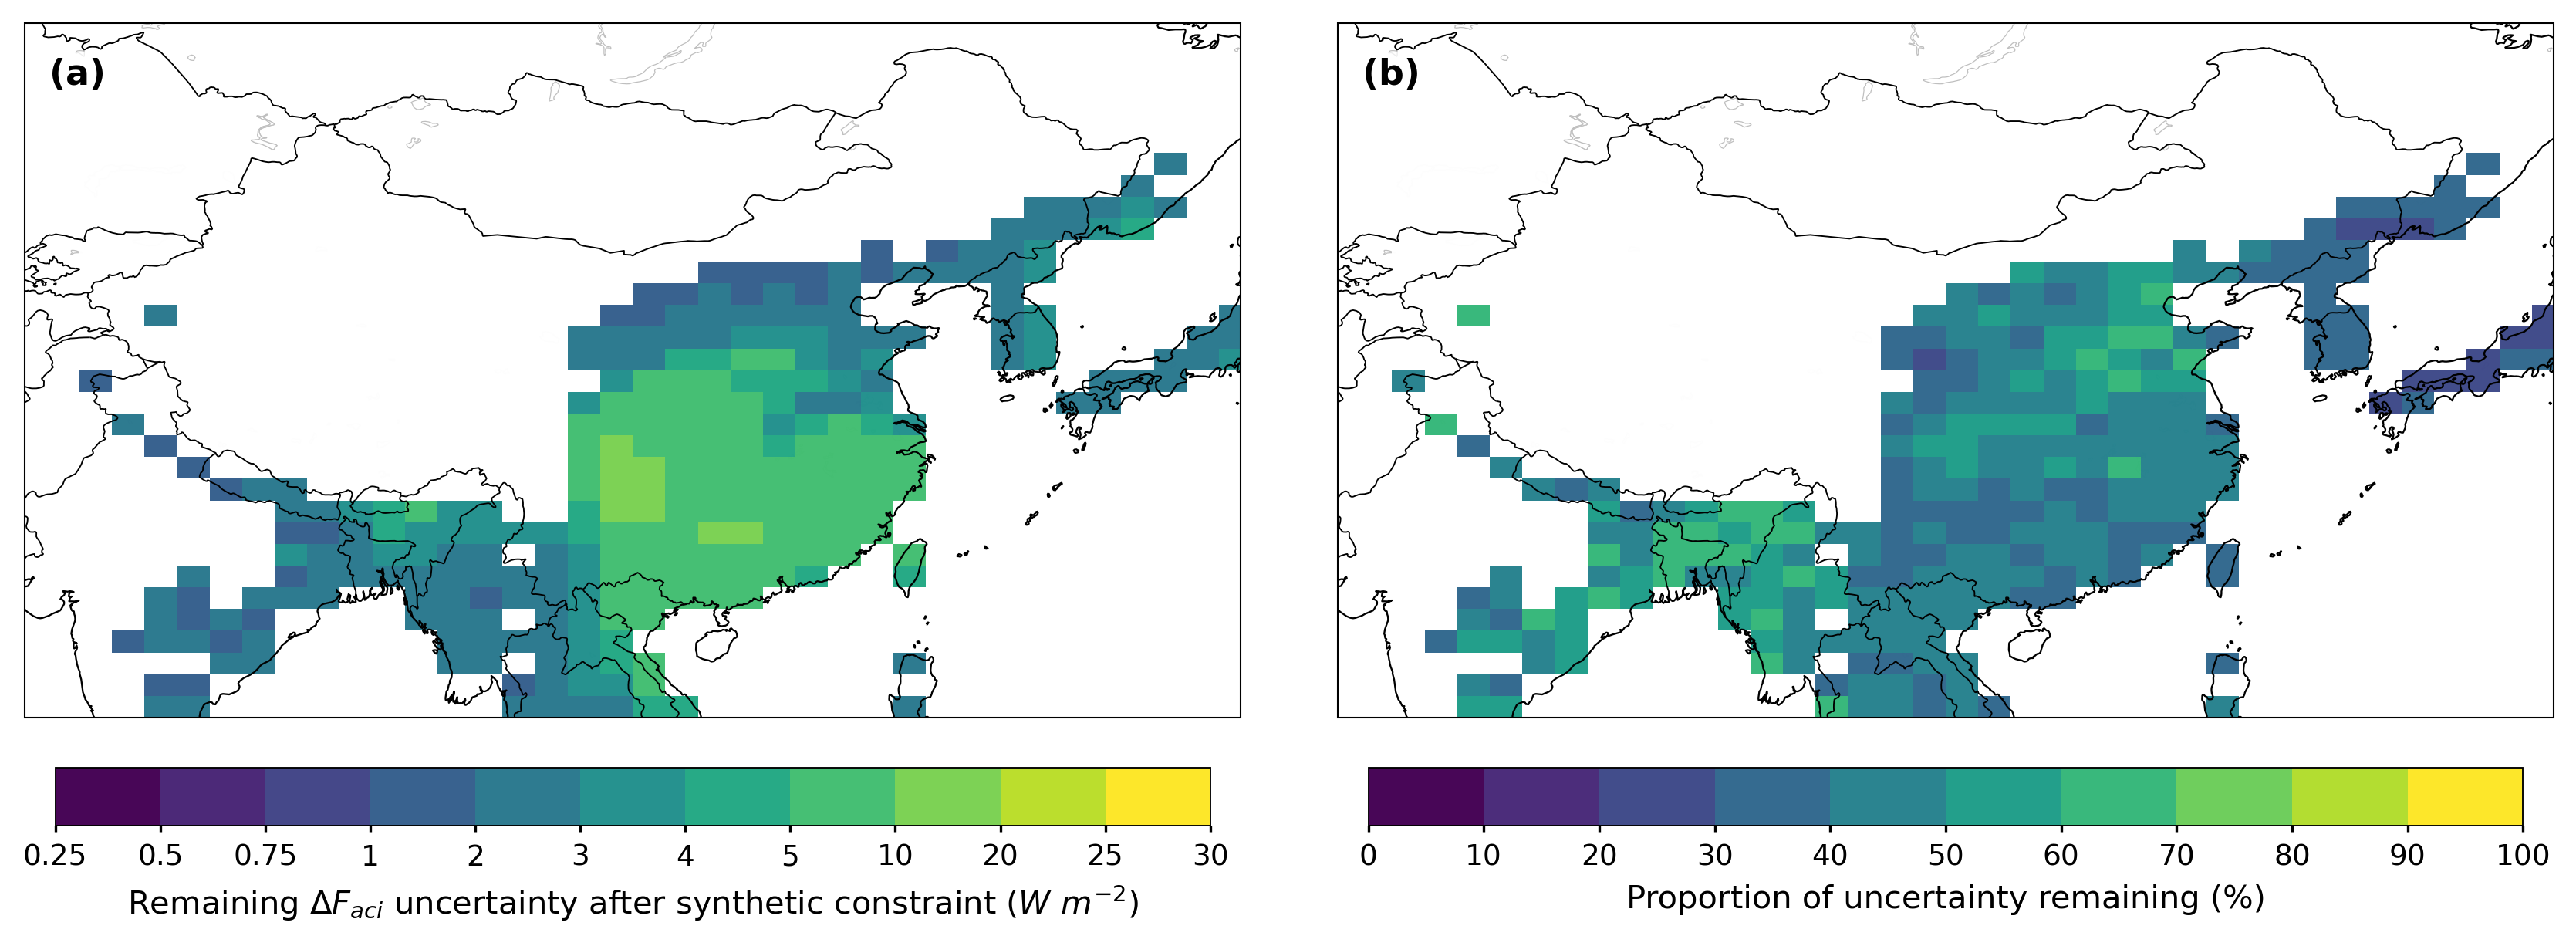

In [1]:
# ============================================================
# FACI uncertainty over China land N96 gridpoints
#
# Cases:
#   1. Full case:
#        1,000,000 variants
#
#   2. OP case:
#        approximately 5,000 optimally constrained variants
#
#   3. Final synthetic constrained case:
#        Cluster 1: Nd + BC, top1000
#        Cluster 5: AAOD + Nd, top1000
#
# Index usage:
#   Follow the original index-reading procedure exactly:
#       indices_decimal = np.loadtxt(index_file)
#       indices = np.array([int(i) for i in indices_decimal], dtype=int)
#
#   Do not subtract 1 from the indices.
#   Do not automatically switch between R and Python indexing.
#   Final top1000 indices refer directly to the 1M sample.
#
# Plot style:
#   No contours and no interpolation.
#   Use the N96 latitude/longitude coordinates from the CSV.
#   Use pcolormesh to display each actual N96 grid box.
#
# Important:
#   Both panels show only grid boxes with full-case uncertainty > 3 W m^-2.
#
# Final 2-panel figure:
#
#   (a) Final synthetic constrained CI90
#
#   (b) Final synthetic constrained CI90
#       / original full CI90 * 100%
#
# Output:
#   Display the figure directly in the Notebook.
#   Do not save the figure.
#   Do not save any CSV file.
#   Do not save any NPZ file.
#   Do not modify existing files.
# ============================================================


import os
import glob
import warnings

import numpy as np
import pandas as pd

import matplotlib as mp
import matplotlib.pyplot as plt

from matplotlib.colors import BoundaryNorm

import cartopy.crs as ccrs
import cartopy.feature as cfeature


try:

    from tqdm.notebook import tqdm

except Exception:

    from tqdm import tqdm


# ============================================================
# 1. Input paths and settings
# ============================================================

gpe_output_dir = (
    "/gws/ssde/j25a/acure/jianxing/"
    "aci/emulation/data_post_emulation"
)


grid_index_file = (
    "/home/users/jianxing/"
    "New_final/ACI_gridpoint_index.csv"
)


sample_file_norm_all = (
    "/home/users/lregayre/R/ACURE/samples/"
    "constrained_multi_million_sample_first_million.dat"
)


# ------------------------------------------------------------
# OP index
# ------------------------------------------------------------

op_indices_file = (
    "/home/users/jianxing/copy/"
    "optimal_constraint_13th_variable_indices_from_1M.dat"
)


# ------------------------------------------------------------
# Final synthetic constrained top1000 indices
# ------------------------------------------------------------

final_indices_file_by_cluster = {

    "1": (
        "/gws/ssde/j25a/acure/jianxing/"
        "Variable/GAM_values/"
        "Step_5_synthetic_constraint/"
        "Step_1_GPE_constraint/"
        "05_candidate_indices/"
        "c1/combo_BC_Nd_AAOD/"
        "c1_combo_BC_Nd_AAOD_"
        "top1000_indices_from_1M.dat"
    ),

    "5": (
        "/gws/ssde/j25a/acure/jianxing/"
        "Variable/GAM_values/"
        "Step_5_synthetic_constraint/"
        "Step_1_GPE_constraint/"
        "05_candidate_indices/"
        "c5/combo_AAOD_Nd/"
        "c5_combo_AAOD_Nd_"
        "top1000_indices_from_1M.dat"
    ),
}


final_combination_by_cluster = {

    "1": "BC+Nd+AAOD",

    "5": "AAOD+Nd",
}


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------
# Notebook only.
# Do not create any output directory.
# Do not save any files.


target_month = "ann"


sample_size_full = 1000000


pred_length_text = "1000000"


china_extent = [
    70,
    140,
    15,
    55,
]


full_uncertainty_threshold = 3.0


# ============================================================
# 2. Helper functions
# ============================================================

def detect_column(
    df,
    candidates,
    required=True,
):

    lower_to_original = {

        c.lower(): c

        for c in df.columns
    }


    for c in candidates:

        if c.lower() in lower_to_original:

            return lower_to_original[
                c.lower()
            ]


    if required:

        raise ValueError(
            f"Cannot find any of columns {candidates}. "
            f"Available columns are: {list(df.columns)}"
        )


    return None


def format_cluster_for_filename(
    x,
):

    try:

        return str(
            int(
                float(x)
            )
        )


    except Exception:

        return str(
            x
        ).strip()


def read_grid_index_csv(
    grid_index_file,
):

    df = pd.read_csv(
        grid_index_file
    )


    cluster_col = detect_column(
        df,
        [
            "cluster"
        ],
        required=True,
    )


    lat_dir_col = detect_column(
        df,
        [
            "lat_dir"
        ],
        required=True,
    )


    lon_dir_col = detect_column(
        df,
        [
            "lon_dir"
        ],
        required=True,
    )


    lat_col = detect_column(
        df,
        [
            "latitude",
            "lat",
            "grid_latitude",
        ],
        required=True,
    )


    lon_col = detect_column(
        df,
        [
            "longitude",
            "lon",
            "grid_longitude",
        ],
        required=True,
    )


    df[
        "_cluster_str"
    ] = (
        df[
            cluster_col
        ]
        .apply(
            format_cluster_for_filename
        )
    )


    df[
        "_lat_dir_use"
    ] = (
        df[
            lat_dir_col
        ]
        .astype(
            str
        )
        .str.strip()
    )


    df[
        "_lon_dir_use"
    ] = (
        df[
            lon_dir_col
        ]
        .astype(
            str
        )
        .str.strip()
    )


    df[
        "_latitude_use"
    ] = (
        df[
            lat_col
        ]
        .astype(
            float
        )
    )


    df[
        "_longitude_use"
    ] = (
        df[
            lon_col
        ]
        .astype(
            float
        )
    )


    print(
        "Grid index loaded:"
    )


    print(
        "  file:",
        grid_index_file,
    )


    print(
        "  n_rows:",
        len(
            df
        ),
    )


    print(
        "  cluster column:",
        cluster_col,
    )


    print(
        "  lat_dir column:",
        lat_dir_col,
    )


    print(
        "  lon_dir column:",
        lon_dir_col,
    )


    print(
        "  latitude column:",
        lat_col,
    )


    print(
        "  longitude column:",
        lon_col,
    )


    print(
        "  latitude range:",
        df[
            "_latitude_use"
        ].min(),
        df[
            "_latitude_use"
        ].max(),
    )


    print(
        "  longitude range:",
        df[
            "_longitude_use"
        ].min(),
        df[
            "_longitude_use"
        ].max(),
    )


    print(
        "  clusters:",
        sorted(
            df[
                "_cluster_str"
            ]
            .unique()
            .tolist()
        ),
    )


    print("")


    return df


def read_indices_like_your_example(
    index_file,
    label,
):

    try:

        indices_decimal = np.loadtxt(
            index_file
        )


        indices = np.array(
            [
                int(i)

                for i in np.ravel(
                    indices_decimal
                )
            ],
            dtype=int,
        )


        print(
            f"{label} index loaded:"
        )


        print(
            "  file:",
            index_file,
        )


        print(
            "  n_index:",
            len(
                indices
            ),
        )


        print(
            "  n_unique:",
            len(
                np.unique(
                    indices
                )
            ),
        )


        print(
            "  min index:",
            indices.min(),
        )


        print(
            "  max index:",
            indices.max(),
        )


        print("")


        return indices


    except Exception as e:

        raise RuntimeError(
            f"Failed to load {label} "
            f"indices from {index_file}: {e}"
        )


def find_gpe_mean_file(
    constraint_text,
):

    exact_file = os.path.join(
        gpe_output_dir,
        (
            f"emulated_mean_values_"
            f"{constraint_text}_"
            f"{pred_length_text}_"
            f"w_o_carb.dat"
        ),
    )


    if os.path.exists(
        exact_file
    ):

        return (
            exact_file,
            exact_file,
        )


    pattern = os.path.join(
        gpe_output_dir,
        (
            f"emulated_mean_values_"
            f"{constraint_text}_"
            f"*_w_o_carb.dat"
        ),
    )


    matches = sorted(
        glob.glob(
            pattern
        )
    )


    if len(
        matches
    ) > 0:

        return (
            matches[
                0
            ],
            exact_file,
        )


    return (
        None,
        exact_file,
    )


def calc_ci90_stats(
    values,
    indices=None,
):

    values = np.asarray(
        values,
        dtype=float,
    )


    if indices is None:

        data = values[
            :sample_size_full
        ]


    else:

        indices = np.asarray(
            indices,
            dtype=int,
        )


        if (
            indices.min() < 0
            or
            indices.max() >= len(
                values
            )
        ):

            raise IndexError(
                f"indices out of range for values length {len(values)}. "
                f"indices min/max = "
                f"{indices.min()} / {indices.max()}"
            )


        data = values[
            indices
        ]


    data = data[
        np.isfinite(
            data
        )
    ]


    if len(
        data
    ) == 0:

        return {

            "n": 0,

            "mean": np.nan,

            "p5": np.nan,

            "p95": np.nan,

            "ci90": np.nan,
        }


    p5, p95 = np.percentile(
        data,
        [
            5,
            95,
        ],
    )


    return {

        "n": int(
            len(
                data
            )
        ),

        "mean": float(
            np.mean(
                data
            )
        ),

        "p5": float(
            p5
        ),

        "p95": float(
            p95
        ),

        "ci90": float(
            p95
            -
            p5
        ),
    }


# ============================================================
# 3. Read grid-point CSV and index files
# ============================================================

grid_df = read_grid_index_csv(
    grid_index_file
)


# ------------------------------------------------------------
# Keep only Cluster 1 and Cluster 2.
#
# Original cluster IDs:
#   1 -> Cluster 1
#   5 -> Cluster 2
# ------------------------------------------------------------

grid_df = grid_df[
    grid_df[
        "_cluster_str"
    ].isin([
        "1",
        "5",
    ])
].copy()


# ------------------------------------------------------------
# OP index
# ------------------------------------------------------------

op_indices = read_indices_like_your_example(
    op_indices_file,
    label="OP",
)


# ------------------------------------------------------------
# Final synthetic constrained indices
# ------------------------------------------------------------

final_indices_by_cluster = {}


for (
    cluster_str,
    index_file,
) in final_indices_file_by_cluster.items():

    final_indices_by_cluster[
        cluster_str
    ] = (
        read_indices_like_your_example(
            index_file,
            label=(
                f"final synthetic c{cluster_str} "
                f"({final_combination_by_cluster[cluster_str]})"
            ),
        )
    )


# ------------------------------------------------------------
# Check that each cluster in the CSV has matching final indices.
# ------------------------------------------------------------

csv_clusters = set(
    grid_df[
        "_cluster_str"
    ]
    .unique()
    .tolist()
)


index_clusters = set(
    final_indices_by_cluster.keys()
)


missing_final_clusters = (
    csv_clusters
    -
    index_clusters
)


if missing_final_clusters:

    raise ValueError(
        "The following clusters in the grid CSV "
        "do not have final synthetic indices: "
        f"{sorted(missing_final_clusters)}"
    )


# ============================================================
# 4. Read GPE output for each CSV grid box and calculate CI
# ============================================================

records = []


n_file_found = 0


n_file_missing = 0


n_processed = 0


for row_id, row in tqdm(
    grid_df.iterrows(),
    total=len(
        grid_df
    ),
    desc="Processing CSV N96 gridpoints",
):

    cluster_str = row[
        "_cluster_str"
    ]


    lat_dir = row[
        "_lat_dir_use"
    ]


    lon_dir = row[
        "_lon_dir_use"
    ]


    latitude = float(
        row[
            "_latitude_use"
        ]
    )


    longitude = float(
        row[
            "_longitude_use"
        ]
    )


    final_indices = (
        final_indices_by_cluster[
            cluster_str
        ]
    )


    final_combination = (
        final_combination_by_cluster[
            cluster_str
        ]
    )


    final_index_file = (
        final_indices_file_by_cluster[
            cluster_str
        ]
    )


    constraint_text = (
        f"{target_month}_"
        f"ACI_"
        f"c{cluster_str}_"
        f"{lat_dir}_"
        f"{lon_dir}"
    )


    (
        mean_file,
        expected_file,
    ) = find_gpe_mean_file(
        constraint_text
    )


    base_record = {

        "row_id":
            row_id,

        "cluster":
            cluster_str,

        "latitude":
            latitude,

        "longitude":
            longitude,

        "lat_dir":
            lat_dir,

        "lon_dir":
            lon_dir,

        "constraint_text":
            constraint_text,

        "expected_file":
            expected_file,

        "final_combination":
            final_combination,

        "final_index_file":
            final_index_file,
    }


    if mean_file is None:

        n_file_missing += 1


        rec = dict(
            base_record
        )


        rec.update({

            "file_found":
                False,

            "mean_file":
                "",

            "error":
                "GPE mean file not found",


            "unc_full":
                np.nan,

            "unc_op":
                np.nan,

            "unc_final":
                np.nan,


            "remaining_pct_from_full":
                np.nan,

            "remaining_pct_from_op":
                np.nan,


            "full_gt3":
                False,


            "mean_full":
                np.nan,

            "mean_op":
                np.nan,

            "mean_final":
                np.nan,


            "p5_full":
                np.nan,

            "p95_full":
                np.nan,


            "p5_op":
                np.nan,

            "p95_op":
                np.nan,


            "p5_final":
                np.nan,

            "p95_final":
                np.nan,


            "n_full":
                0,

            "n_op":
                0,

            "n_final":
                0,
        })


        records.append(
            rec
        )


        continue


    n_file_found += 1


    try:

        values = np.loadtxt(
            mean_file
        )


        # ====================================================
        # Full 1M
        # ====================================================

        stats_full = calc_ci90_stats(
            values,
            indices=None,
        )


        # ====================================================
        # OP approximately 5000
        # ====================================================

        stats_op = calc_ci90_stats(
            values,
            indices=op_indices,
        )


        # ====================================================
        # Final cluster-specific top1000
        # ====================================================

        stats_final = calc_ci90_stats(
            values,
            indices=final_indices,
        )


        unc_full = stats_full[
            "ci90"
        ]


        unc_op = stats_op[
            "ci90"
        ]


        unc_final = stats_final[
            "ci90"
        ]


        # ----------------------------------------------------
        # Final relative to original full case
        # ----------------------------------------------------

        if (
            np.isfinite(
                unc_full
            )
            and
            unc_full > 0
        ):

            remaining_pct_from_full = (
                unc_final
                /
                unc_full
                *
                100.0
            )


        else:

            remaining_pct_from_full = (
                np.nan
            )


        # ----------------------------------------------------
        # Final relative to OP
        #
        # Retain this calculation from the original code,
        # but do not draw this panel in the current version.
        # ----------------------------------------------------

        if (
            np.isfinite(
                unc_op
            )
            and
            unc_op > 0
        ):

            remaining_pct_from_op = (
                unc_final
                /
                unc_op
                *
                100.0
            )


        else:

            remaining_pct_from_op = (
                np.nan
            )


        # ----------------------------------------------------
        # Original uncertainty-threshold mask
        # ----------------------------------------------------

        full_gt3 = bool(
            np.isfinite(
                unc_full
            )
            and
            unc_full
            >
            full_uncertainty_threshold
        )


        rec = dict(
            base_record
        )


        rec.update({

            "file_found":
                True,

            "mean_file":
                mean_file,

            "error":
                "",


            "unc_full":
                unc_full,

            "unc_op":
                unc_op,

            "unc_final":
                unc_final,


            "remaining_pct_from_full":
                remaining_pct_from_full,

            "remaining_pct_from_op":
                remaining_pct_from_op,


            "full_gt3":
                full_gt3,


            "mean_full":
                stats_full[
                    "mean"
                ],

            "mean_op":
                stats_op[
                    "mean"
                ],

            "mean_final":
                stats_final[
                    "mean"
                ],


            "p5_full":
                stats_full[
                    "p5"
                ],

            "p5_op":
                stats_op[
                    "p5"
                ],

            "p5_final":
                stats_final[
                    "p5"
                ],


            "p95_full":
                stats_full[
                    "p95"
                ],

            "p95_op":
                stats_op[
                    "p95"
                ],

            "p95_final":
                stats_final[
                    "p95"
                ],


            "n_full":
                stats_full[
                    "n"
                ],

            "n_op":
                stats_op[
                    "n"
                ],

            "n_final":
                stats_final[
                    "n"
                ],
        })


        records.append(
            rec
        )


        n_processed += 1


    except Exception as e:

        rec = dict(
            base_record
        )


        rec.update({

            "file_found":
                True,

            "mean_file":
                mean_file,

            "error":
                (
                    "Failed to read/process file: "
                    f"{e}"
                ),


            "unc_full":
                np.nan,

            "unc_op":
                np.nan,

            "unc_final":
                np.nan,


            "remaining_pct_from_full":
                np.nan,

            "remaining_pct_from_op":
                np.nan,


            "full_gt3":
                False,


            "mean_full":
                np.nan,

            "mean_op":
                np.nan,

            "mean_final":
                np.nan,


            "p5_full":
                np.nan,

            "p95_full":
                np.nan,


            "p5_op":
                np.nan,

            "p95_op":
                np.nan,


            "p5_final":
                np.nan,

            "p95_final":
                np.nan,


            "n_full":
                0,

            "n_op":
                0,

            "n_final":
                0,
        })


        records.append(
            rec
        )


# ============================================================
# Build summary dataframe
# ============================================================

summary_df = pd.DataFrame(
    records
)


print("")


print(
    "Processing summary:"
)


print(
    "  CSV rows:",
    len(
        grid_df
    ),
)


print(
    "  GPE files found:",
    n_file_found,
)


print(
    "  GPE files missing:",
    n_file_missing,
)


print(
    "  successfully processed:",
    n_processed,
)


print(
    "  finite full:",
    int(
        np.isfinite(
            summary_df[
                "unc_full"
            ]
        ).sum()
    ),
)


print(
    "  finite OP:",
    int(
        np.isfinite(
            summary_df[
                "unc_op"
            ]
        ).sum()
    ),
)


print(
    "  finite final:",
    int(
        np.isfinite(
            summary_df[
                "unc_final"
            ]
        ).sum()
    ),
)


print(
    "  finite final/original ratio:",
    int(
        np.isfinite(
            summary_df[
                "remaining_pct_from_full"
            ]
        ).sum()
    ),
)


print(
    "  full > 3 W m^-2:",
    int(
        summary_df[
            "full_gt3"
        ].sum()
    ),
)


print("")


print(
    "Processed gridpoints by cluster:"
)


print(
    summary_df[
        summary_df[
            "file_found"
        ]
        ==
        True
    ]
    .groupby(
        "cluster"
    )
    .size()
)


print("")


# ============================================================
# 5. Notebook only
#
# Do not save any files.
# ============================================================

try:

    display(
        summary_df.head()
    )


except Exception:

    print(
        summary_df.head()
    )


# ============================================================
# 6. N96 gridbox plotting functions
# ============================================================

def centers_to_edges(
    centers,
):

    centers = np.asarray(
        centers,
        dtype=float,
    )


    centers = np.sort(
        np.unique(
            centers
        )
    )


    if len(
        centers
    ) == 1:

        delta = 1.0


        return np.array(
            [
                centers[
                    0
                ]
                -
                delta
                /
                2.0,

                centers[
                    0
                ]
                +
                delta
                /
                2.0,
            ]
        )


    midpoints = (
        centers[
            :-1
        ]
        +
        centers[
            1:
        ]
    ) / 2.0


    first_edge = (
        centers[
            0
        ]
        -
        (
            midpoints[
                0
            ]
            -
            centers[
                0
            ]
        )
    )


    last_edge = (
        centers[
            -1
        ]
        +
        (
            centers[
                -1
            ]
            -
            midpoints[
                -1
            ]
        )
    )


    edges = np.concatenate(
        [
            [
                first_edge
            ],

            midpoints,

            [
                last_edge
            ],
        ]
    )


    return edges


def make_pcolormesh_grid(
    plot_df,
    value_col,
):

    grid = plot_df.pivot_table(

        index=
            "latitude",

        columns=
            "longitude",

        values=
            value_col,

        aggfunc=
            "mean",
    )


    grid = grid.sort_index(
        axis=0
    )


    grid = grid.sort_index(
        axis=1
    )


    lat_centers = (
        grid.index
        .values
        .astype(
            float
        )
    )


    lon_centers = (
        grid.columns
        .values
        .astype(
            float
        )
    )


    lat_edges = centers_to_edges(
        lat_centers
    )


    lon_edges = centers_to_edges(
        lon_centers
    )


    values_2d = grid.values.astype(
        float
    )


    values_2d = np.ma.masked_invalid(
        values_2d
    )


    return (
        lon_edges,
        lat_edges,
        values_2d,
    )


def plot_gridbox_fig2_cluster_style(
    summary_df,
    extent=(70, 140, 15, 55),
    marker_size=72,
    full_threshold=3.0,
):
    """
    Two panels in a 1 x 2 layout:

      (a) Final synthetic constrained uncertainty

      (b) Final / original full case * 100%

    Plotting method:

      - No contours
      - No interpolation
      - Use longitude/latitude values directly from the CSV
      - Use pcolormesh to draw each N96 grid point
        as its actual grid box

      - Both panels show only grid boxes with:
        full uncertainty > 3 W m^-2
    """


    # --------------------------------------------------------
    # Valid values
    # --------------------------------------------------------

    plot_df_all = summary_df[

        (
            summary_df[
                "file_found"
            ]
            ==
            True
        )

        &

        np.isfinite(
            summary_df[
                "longitude"
            ]
        )

        &

        np.isfinite(
            summary_df[
                "latitude"
            ]
        )

        &

        np.isfinite(
            summary_df[
                "unc_full"
            ]
        )

        &

        np.isfinite(
            summary_df[
                "unc_final"
            ]
        )

        &

        np.isfinite(
            summary_df[
                "remaining_pct_from_full"
            ]
        )

    ].copy()


    # --------------------------------------------------------
    # Apply original full uncertainty threshold
    # --------------------------------------------------------

    plot_df = plot_df_all[

        plot_df_all[
            "unc_full"
        ]

        >

        full_threshold

    ].copy()


    if len(
        plot_df
    ) == 0:

        raise ValueError(
            f"No valid gridpoints with "
            f"full uncertainty > "
            f"{full_threshold} W m^-2."
        )


    # --------------------------------------------------------
    # Print plotting range
    # --------------------------------------------------------

    print(
        "Plotting summary:"
    )


    print(
        "  valid gridpoints before full>3 filter:",
        len(
            plot_df_all
        ),
    )


    print(
        f"  valid gridpoints after "
        f"full>{full_threshold} filter:",
        len(
            plot_df
        ),
    )


    print(
        "  longitude range:",
        plot_df[
            "longitude"
        ].min(),
        plot_df[
            "longitude"
        ].max(),
    )


    print(
        "  latitude range:",
        plot_df[
            "latitude"
        ].min(),
        plot_df[
            "latitude"
        ].max(),
    )


    print(
        "  final uncertainty range:",
        plot_df[
            "unc_final"
        ].min(),
        plot_df[
            "unc_final"
        ].max(),
    )


    print(
        "  final / original percentage range:",
        plot_df[
            "remaining_pct_from_full"
        ].min(),
        plot_df[
            "remaining_pct_from_full"
        ].max(),
    )


    print("")


    # --------------------------------------------------------
    # Original uncertainty levels
    # --------------------------------------------------------

    levels_percentage = (
        np.arange(
            11
        )
        *
        10
    )


    levels_variance = [
        0.25,
        0.5,
        0.75,
        1.0,
        2.0,
        3.0,
        4.0,
        5.0,
        10.0,
        20.0,
        25.0,
        30.0,
    ]


    levels_variance_tick_labels = [
        "0.25",
        "0.5",
        "0.75",
        "1",
        "2",
        "3",
        "4",
        "5",
        "10",
        "20",
        "25",
        "30",
    ]


    cmap_pos = plt.get_cmap(
        "viridis"
    ).copy()


    cmap_pos2 = plt.get_cmap(
        "viridis"
    ).copy()


    cmap_pos.set_bad(
        color="white",
        alpha=0.0,
    )


    cmap_pos2.set_bad(
        color="white",
        alpha=0.0,
    )


    norm_variance = BoundaryNorm(
        levels_variance,
        ncolors=cmap_pos.N,
        clip=True,
    )


    norm_percentage = BoundaryNorm(
        levels_percentage,
        ncolors=cmap_pos2.N,
        clip=True,
    )


    # --------------------------------------------------------
    # Font style
    # --------------------------------------------------------

    font_size = 9


    mp.rcParams[
        "axes.labelsize"
    ] = (
        font_size
        *
        0.9
    )


    mp.rcParams[
        "axes.linewidth"
    ] = 0.5


    mp.rcParams[
        "axes.titlesize"
    ] = (
        font_size
        *
        2.0
    )


    mp.rcParams[
        "legend.fontsize"
    ] = (
        font_size
        *
        0.8
    )


    mp.rcParams[
        "xtick.labelsize"
    ] = font_size


    mp.rcParams[
        "ytick.labelsize"
    ] = font_size


    DELTA = "\u0394"


    fontsize_legends = 9


    fontsize_text = 10


    fontsize_subtext = 11


    shrink_size = 0.95


    # --------------------------------------------------------
    # Figure
    #
    # 1 x 2 horizontal layout
    # --------------------------------------------------------

    fig = plt.figure(
        figsize=(
            11.5,
            5.2,
        ),
        dpi=300,
    )


    # ========================================================
    # Two panels
    #
    # (a) Synthetic constrained uncertainty
    #
    # (b) Final / full percentage
    # ========================================================

    panel_info = [

        (
            "unc_final",

            "(a)",

            (
                "Remaining "
                +
                DELTA
                +
                "$F_{aci}$ uncertainty "
                +
                "after synthetic constraint "
                +
                "($W\\ m^{-2}$)"
            ),

            norm_variance,

            cmap_pos,

            levels_variance,

            levels_variance_tick_labels,
        ),


        (
            "remaining_pct_from_full",

            "(b)",

            (
                "Proportion of uncertainty "
                "remaining (%)"
            ),

            norm_percentage,

            cmap_pos2,

            levels_percentage,

            None,
        ),
    ]


    # --------------------------------------------------------
    # Plot panels
    # --------------------------------------------------------

    for ipanel, (
        col,
        panel_label,
        cbar_label,
        norm,
        cmap,
        ticks,
        ticklabels,
    ) in enumerate(
        panel_info,
        start=1,
    ):

        ax = fig.add_subplot(
            1,
            2,
            ipanel,
            projection=ccrs.PlateCarree(),
        )


        ax.set_extent(
            extent,
            crs=ccrs.PlateCarree(),
        )


        # ----------------------------------------------------
        # White background
        # ----------------------------------------------------

        ax.set_facecolor(
            "white"
        )


        ax.add_feature(
            cfeature.LAND,
            facecolor="white",
            edgecolor="none",
            zorder=0,
        )


        ax.add_feature(
            cfeature.OCEAN,
            facecolor="white",
            edgecolor="none",
            zorder=0,
        )


        ax.add_feature(
            cfeature.LAKES,
            facecolor="white",
            edgecolor="0.75",
            linewidth=0.3,
            zorder=1,
        )


        ax.coastlines(
            resolution="50m",
            linewidth=0.55,
            color="black",
            zorder=3,
        )


        ax.add_feature(
            cfeature.BORDERS,
            linewidth=0.45,
            edgecolor="black",
            zorder=3,
        )


        # ----------------------------------------------------
        # pcolormesh
        #
        # No interpolation
        # ----------------------------------------------------

        (
            lon_edges,
            lat_edges,
            values_2d,
        ) = make_pcolormesh_grid(
            plot_df,
            col,
        )


        pc = ax.pcolormesh(

            lon_edges,

            lat_edges,

            values_2d,

            cmap=
                cmap,

            norm=
                norm,

            transform=
                ccrs.PlateCarree(),

            shading=
                "flat",

            edgecolors=
                "none",

            linewidth=
                0.0,

            alpha=
                0.98,

            zorder=
                2,
        )


        # ----------------------------------------------------
        # Panel label
        # ----------------------------------------------------

        ax.text(

            0.02,

            0.95,

            panel_label,

            transform=
                ax.transAxes,

            fontsize=
                fontsize_subtext,

            fontweight=
                "bold",

            va=
                "top",

            ha=
                "left",

            bbox=dict(

                facecolor=
                    "white",

                edgecolor=
                    "none",

                alpha=
                    0.70,

                pad=
                    1.5,
            ),

            zorder=
                5,
        )


        # ----------------------------------------------------
        # Colorbar
        # ----------------------------------------------------

        cbar = plt.colorbar(

            pc,

            ax=
                ax,

            ticks=
                ticks,

            shrink=
                shrink_size,

            orientation=
                "horizontal",

            pad=
                0.05,

            use_gridspec=
                True,
        )


        cbar.ax.set_xlabel(

            cbar_label,

            fontsize=
                fontsize_text,
        )


        cbar.ax.tick_params(

            labelsize=
                fontsize_legends,

            length=
                2,
        )


        if ticklabels is not None:

            cbar.set_ticklabels(
                ticklabels
            )


        cbar.outline.set_linewidth(
            0.45
        )


    # --------------------------------------------------------
    # Layout
    # --------------------------------------------------------

    plt.subplots_adjust(

        left=
            0.035,

        right=
            0.985,

        top=
            0.94,

        bottom=
            0.10,

        wspace=
            0.08,
    )


    # ========================================================
    # Notebook only
    #
    # Display only
    # Do not save
    # ========================================================

    plt.show()


# ============================================================
# 7. Call the plotting function
# ============================================================

plot_gridbox_fig2_cluster_style(

    summary_df,

    extent=
        china_extent,

    marker_size=
        72,

    full_threshold=
        full_uncertainty_threshold,
)